# 02 · Baselines: los rivales que la red tiene que vencer

## ¿Qué es un baseline y por qué importa?

Un baseline es un modelo simple que sirve de **vara de comparación**. Sin él, un número como "recall@10 = 18%" no significa nada: ¿es bueno? ¿Malo? Solo sabemos que un modelo es bueno si le gana a las alternativas simples.

En recomendación esto es especialmente importante. Hay muchos papers donde redes neuronales sofisticadas **pierden** contra baselines bien ajustados. Vamos a hacer el trabajo honesto: ajustar bien los rivales.

## Los cuatro baselines

| Modelo | Idea | Con historial | Cold start |
|---|---|:-:|:-:|
| **Popularidad** | Recomendar lo más popular a todo el mundo | ✔ | ✔ |
| **Popularidad por segmento** | Lo más popular entre personas con tu tono y tipo de piel | ✔ | ✔ |
| **ALS** (factorización de matrices) | Aprende un "mapa de gustos" a partir del historial | ✔ | ✘ |
| **Híbrido perfil → ALS** | Predice, desde el perfil, dónde caería una persona nueva en ese mapa | — | ✔ |

> El plan original incluía LightFM, pero esa librería no se puede instalar en Windows. El híbrido perfil → ALS cumple el mismo papel (un rival que combina historial y perfil).

## Las métricas

Para cada persona, el modelo arma un **top 10**. Después:

- **Recall@10**: de los productos que le gustaron (y escondimos), ¿qué proporción quedó en su top 10? Con historial hay un solo producto escondido, así que es "¿acertó o no?".
- **NDCG@10**: como el recall, pero **premia acertar arriba**. Acertar en el puesto 1 vale 1; en el puesto 10 vale ~0,29.
- **Cobertura**: ¿qué proporción del catálogo aparece en al menos un top 10? Si es muy baja, el modelo recomienda siempre lo mismo (**sesgo de popularidad**).

**Referencia:** recomendar al azar daría un recall@10 de 10/2.351 ≈ **0,4%**.

## Regla de oro: en este notebook solo miramos **validación**

Ajustamos los hiperparámetros mirando validación. **Test no se toca** hasta el final del proyecto, cuando comparemos todos los modelos (incluida la red) una sola vez.

El código de los modelos está en `src/baselines.py` y la evaluación en `src/evaluate.py`.

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
threadpool_limits(1, "blas")  # recomendado por la librería implicit: evita que BLAS compita con sus propios hilos

from src.data import TONE_GROUP_ORDER
from src.splits import load_splits
from src.evaluate import ItemIndex, evaluate, summarize, by_tone
from src.baselines import Popularity, SegmentPopularity, ALSRecommender, ProfileToALS

FIG = ROOT / "reports" / "figures"
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORES = {"Popularidad": "#9a9a9a", "Pop. por segmento": "#d9a0b4", "ALS": "#c2577a", "Híbrido perfil→ALS": "#4a78b0"}

s = load_splits()
idx = ItemIndex(s.items)
N = len(idx)
print(f"Catálogo: {N:,} productos | train: {len(s.train):,} positivos")
print(f"Validación con historial: {len(s.val_warm):,} personas | validación cold start: {s.val_cold.author_id.nunique():,} personas")

def eval_warm(model):  # personas conocidas: no recomendamos lo que ya reseñaron
    return evaluate(model, s.val_warm, s.train, s.users, idx, exclude_train=True)

def eval_cold(model):  # personas nuevas: no hay nada que excluir
    return evaluate(model, s.val_cold, s.train, s.users, idx, exclude_train=False)

resultados = {}  # acá guardamos el resultado por persona de cada modelo final

Catálogo: 2,351 productos | train: 697,572 positivos
Validación con historial: 41,509 personas | validación cold start: 21,508 personas


## 1 · Popularidad

El rival más simple: cuenta cuántos positivos tiene cada producto en train y recomienda los 10 primeros a todo el mundo (excepto los que la persona ya reseñó).

In [2]:
pop = Popularity(s.train, idx)
resultados[("Popularidad", "historial")] = eval_warm(pop)
resultados[("Popularidad", "cold start")] = eval_cold(pop)

display(pd.DataFrame([
    summarize(resultados[("Popularidad", "historial")], N, "con historial"),
    summarize(resultados[("Popularidad", "cold start")], N, "cold start"),
]))
top10 = s.items.iloc[np.argsort(-pop.scores)[:10]][["product_name", "brand_name", "secondary_category"]]
display(top10.reset_index(drop=True))

,recall@10,± recall,ndcg@10,± ndcg,cobertura,personas
con historial,0.0467,0.0010,0.0249,0.0006,0.0094,"41,509.0000"
cold start,0.0988,0.0019,0.0583,0.0012,0.0043,"21,508.0000"


,product_name,brand_name,secondary_category
0,Lip Sleeping Mask Intense Hydration with Vitam...,LANEIGE,Lip Balms & Treatments
1,Soy Hydrating Gentle Face Cleanser,fresh,Cleansers
2,Alpha Beta Extra Strength Daily Peel Pads,Dr. Dennis Gross Skincare,Treatments
3,100 percent Pure Argan Oil,Josie Maran,Moisturizers
4,Ultra Repair Cream Intense Hydration,First Aid Beauty,Moisturizers
5,The True Cream Aqua Bomb,belif,Moisturizers
6,Green Clean Makeup Removing Cleansing Balm,Farmacy,Cleansers
7,Green Clean Makeup Meltaway Cleansing Balm Lim...,Farmacy,Cleansers
8,Rosebud Salve,Rosebud Perfume Co.,Lip Balms & Treatments
9,Niacinamide 10% + Zinc 1% Oil Control Serum,The Ordinary,Treatments


**¿Por qué la popularidad anda mejor en cold start que con historial?** Dos razones:
1. Con historial **excluimos** lo que la persona ya reseñó. Las personas con historial ya probaron muchos de los productos populares, y lo que queda por adivinar es menos obvio.
2. En cold start las personas tienen en promedio 2 positivos para adivinar (más chances de acertar alguno). Las personas nuevas también suelen empezar por lo popular.

Por eso **no comparamos números entre escenarios**: cada escenario tiene su propia vara.

## 2 · Popularidad por segmento

Mismo principio, pero contando solo entre personas parecidas. Dos decisiones a ajustar:

- **Qué define el segmento**: ¿solo el tono? ¿Tono y tipo de piel? ¿Todo el perfil?
- **`alpha` (smoothing)**: los segmentos chicos tienen pocos datos y su ranking es ruidoso. `alpha` mezcla con la popularidad global, como si sumáramos `alpha` positivos "imaginarios" repartidos como en la población. Con `alpha` → ∞ volvemos a la popularidad global.

Ajustamos en **cold start**, que es donde este modelo tiene sentido.

In [3]:
segmentos = {
    "tono": ["skin_tone"],
    "tipo": ["skin_type"],
    "tono × tipo": ["skin_tone", "skin_type"],
    "perfil completo": ["skin_tone", "skin_type", "eye_color", "hair_color"],
}
grid = []
for nombre, cols in segmentos.items():
    for alpha in [10, 100, 1000, 10000]:
        res = eval_cold(SegmentPopularity(s.train, s.users, idx, cols=cols, alpha=alpha))
        grid.append({"segmento": nombre, "alpha": alpha, "recall@10": res.recall.mean(), "ndcg@10": res.ndcg.mean()})
grid_seg = pd.DataFrame(grid)
display(grid_seg.pivot(index="segmento", columns="alpha", values="recall@10").loc[list(segmentos)])
mejor_seg = grid_seg.loc[grid_seg["recall@10"].idxmax()]
print(f"Mejor: segmento = {mejor_seg.segmento}, alpha = {mejor_seg.alpha}, recall@10 = {mejor_seg['recall@10']:.4f}")

alpha,10,100,1000,10000
segmento,,,,
tono,0.1102,0.1102,0.1100,0.1103
tipo,0.1070,0.1070,0.1070,0.1070
tono × tipo,0.1158,0.1158,0.1154,0.1130
perfil completo,0.1332,0.1334,0.1317,0.1216


Mejor: segmento = perfil completo, alpha = 100, recall@10 = 0.1334


In [4]:
seg = SegmentPopularity(s.train, s.users, idx, cols=segmentos[mejor_seg.segmento], alpha=mejor_seg.alpha)
resultados[("Pop. por segmento", "historial")] = eval_warm(seg)
resultados[("Pop. por segmento", "cold start")] = eval_cold(seg)

## 3 · ALS: factorización de matrices

### La idea

Imaginá una tabla enorme: 387 mil personas × 2.351 productos, con un 1 donde a alguien le gustó un producto. Está casi vacía (99,9% de ceros). ALS la **comprime**: le asigna a cada persona y a cada producto un vector de, digamos, 64 números, de forma que **persona · producto** sea alto donde había un 1.

Esos 64 números son un **"mapa de gustos"** aprendido: productos que le gustan a la misma gente quedan cerca, y cada persona queda cerca de lo que le gusta. Nadie le dice al modelo qué significa cada número; los descubre solo (por ejemplo, uno podría terminar separando "anti-age" de "acné").

### Hiperparámetros

- **`factors`**: cuántos números por vector. Más = más capacidad, pero más riesgo de sobreajustar.
- **`regularization`**: penaliza vectores muy grandes (controla el sobreajuste).
- **`alpha`**: cuánto más pesa un positivo observado que un "no observado". Recordá que "no reseñado" no significa "no le gustó".

Probamos una grilla chica. Cada entrenamiento tarda menos de un minuto.

In [5]:
grid = []
for factors in [32, 64, 128]:
    for alpha in [5, 20, 50]:
        t = time.time()
        res = eval_warm(ALSRecommender(s.train, idx, factors=factors, alpha=alpha, regularization=0.05))
        grid.append({"factors": factors, "alpha": alpha, "recall@10": res.recall.mean(), "ndcg@10": res.ndcg.mean(),
                     "segundos": time.time() - t})
grid_als = pd.DataFrame(grid)
display(grid_als.pivot(index="factors", columns="alpha", values="recall@10"))
mejor_als = grid_als.loc[grid_als["recall@10"].idxmax()]
print(f"Mejor: factors = {int(mejor_als.factors)}, alpha = {mejor_als.alpha}, recall@10 = {mejor_als['recall@10']:.4f}")

C:\Users\cande\Universidad Austral\Recomendador Skincare\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\cande\Universidad Austral\Recomendador Skincare\.venv\Lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 12 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


alpha,5,20,50
factors,,,
32,0.1256,0.1451,0.1516
64,0.1412,0.1608,0.1617
128,0.1466,0.1608,0.1582


Mejor: factors = 64, alpha = 50.0, recall@10 = 0.1617


In [6]:
grid = []
for reg in [0.05, 0.5, 5.0, 20.0, 50.0]:
    res = eval_warm(ALSRecommender(s.train, idx, factors=int(mejor_als.factors), alpha=mejor_als.alpha, regularization=reg))
    grid.append({"regularization": reg, "recall@10": res.recall.mean(), "ndcg@10": res.ndcg.mean()})
grid_reg = pd.DataFrame(grid)
display(grid_reg)
mejor_reg = grid_reg.loc[grid_reg["recall@10"].idxmax(), "regularization"]

,regularization,recall@10,ndcg@10
0,0.0500,0.1617,0.0956
1,0.5000,0.1615,0.0956
2,5.0000,0.1670,0.0977
3,20.0000,0.1693,0.0972
4,50.0000,0.1667,0.0962


In [7]:
als = ALSRecommender(s.train, idx, factors=int(mejor_als.factors), alpha=mejor_als.alpha, regularization=mejor_reg)
resultados[("ALS", "historial")] = eval_warm(als)
print(f"ALS final: factors={int(mejor_als.factors)}, alpha={mejor_als.alpha}, regularization={mejor_reg}")

ALS final: factors=64, alpha=50.0, regularization=20.0


## 4 · Híbrido perfil → ALS (para cold start)

ALS no puede puntuar a una persona nueva: no tiene su vector. Pero sí tiene los vectores de 387 mil personas **y** sus perfiles. Entonces:

1. Entrenamos una **regresión Ridge**: perfil (en one-hot) → vector ALS de la persona.
2. Para una persona nueva: perfil → vector predicho → puntaje contra todos los productos.

Es la idea central de la red two-tower, pero en dos pasos separados y lineal. Si la red le gana, sabremos que aprender todo junto (y de forma no lineal) ayuda.

Ajustamos `min_pos` (solo usamos personas con al menos ese número de positivos, porque sus vectores están mejor estimados) y la regularización de Ridge.

In [8]:
grid = []
for min_pos in [1, 2, 3, 5]:
    for ridge_alpha in [0.1, 10, 1000]:
        res = eval_cold(ProfileToALS(als, s.train, s.users, min_pos=min_pos, ridge_alpha=ridge_alpha))
        grid.append({"min_pos": min_pos, "ridge_alpha": ridge_alpha, "recall@10": res.recall.mean()})
grid_hyb = pd.DataFrame(grid)
display(grid_hyb.pivot(index="min_pos", columns="ridge_alpha", values="recall@10"))
mejor_hyb = grid_hyb.loc[grid_hyb["recall@10"].idxmax()]
hyb = ProfileToALS(als, s.train, s.users, min_pos=int(mejor_hyb.min_pos), ridge_alpha=mejor_hyb.ridge_alpha)
resultados[("Híbrido perfil→ALS", "cold start")] = eval_cold(hyb)

ridge_alpha,0.1000,10.0000,"1,000.0000"
min_pos,,,
1,0.1270,0.1270,0.1275
2,0.1077,0.1077,0.1072
3,0.0961,0.0965,0.0966
5,0.0510,0.0513,0.0423


## 5 · La tabla de resultados (validación)

In [9]:
tabla = pd.DataFrame([summarize(r, N, f"{m} | {e}") for (m, e), r in resultados.items()])
tabla.index = pd.MultiIndex.from_tuples([k for k in resultados], names=["modelo", "escenario"])
tabla = tabla.sort_index(level="escenario")
display(tabla[["recall@10", "± recall", "ndcg@10", "cobertura"]])
tabla.to_csv(ROOT / "reports" / "02_baselines_val.csv")

,,recall@10,± recall,ndcg@10,cobertura
modelo,escenario,,,,
Híbrido perfil→ALS,cold start,0.1275,0.0021,0.0773,0.0481
Pop. por segmento,cold start,0.1334,0.0022,0.0835,0.2629
Popularidad,cold start,0.0988,0.0019,0.0583,0.0043
ALS,historial,0.1693,0.0018,0.0972,0.4904
Pop. por segmento,historial,0.0547,0.0011,0.0293,0.3122
Popularidad,historial,0.0467,0.0010,0.0249,0.0094


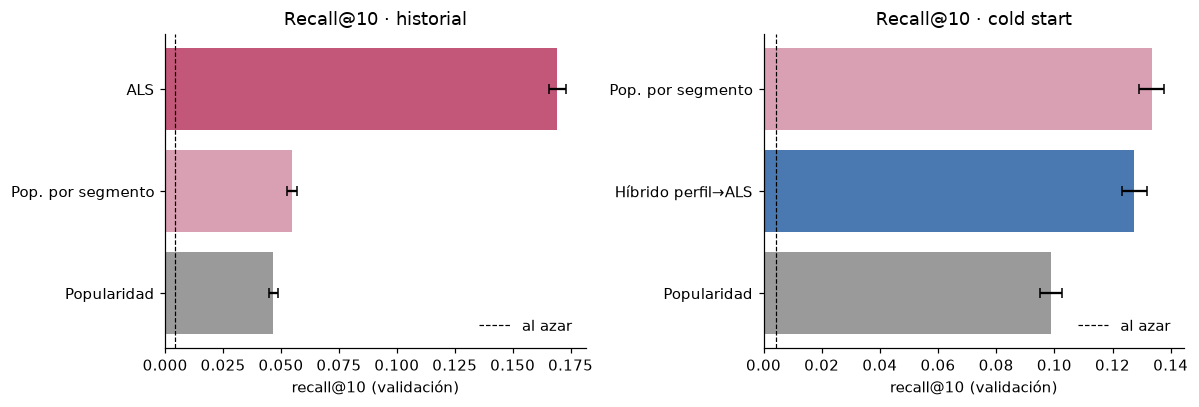

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
for ax, esc in zip(axes, ["historial", "cold start"]):
    t = tabla.xs(esc, level="escenario").sort_values("recall@10")
    ax.barh(t.index, t["recall@10"], xerr=1.96 * t["± recall"], color=[COLORES[m] for m in t.index], capsize=3)
    ax.axvline(10 / N, ls="--", color="k", lw=0.8, label="al azar")
    ax.set(title=f"Recall@10 · {esc}", xlabel="recall@10 (validación)")
    ax.legend(loc="lower right", frameon=False)
plt.tight_layout(); plt.savefig(FIG / "02_baselines_recall.png"); plt.show()

## 6 · Primera mirada a la fairness: ¿funciona igual para todos los tonos?

Mismo recall, separado por grupo de tono. Las barras de error son intervalos del 95% (±1,96 errores estándar).

In [11]:
filas = []
for (m, e), r in resultados.items():
    bt = by_tone(r)
    bt["modelo"], bt["escenario"] = m, e
    filas.append(bt.reset_index())
tono = pd.concat(filas)
display(tono.pivot_table(index=["escenario", "modelo"], columns="tone_group", values="mean")[TONE_GROUP_ORDER + ["desconocido"]])

tone_group                     claro  light  medio    tan  oscuro  desconocido
escenario  modelo                                                             
cold start Híbrido perfil→ALS 0.1079 0.1060 0.1125 0.1019  0.1192       0.2255
           Pop. por segmento  0.1147 0.1129 0.1129 0.1004  0.1174       0.2420
           Popularidad        0.0922 0.0904 0.0855 0.0886  0.0850       0.1518
historial  ALS                0.1663 0.1609 0.1760 0.1893  0.1717       0.1738
           Pop. por segmento  0.0564 0.0490 0.0496 0.0597  0.0590       0.1305
           Popularidad        0.0522 0.0439 0.0415 0.0481  0.0463       0.0762

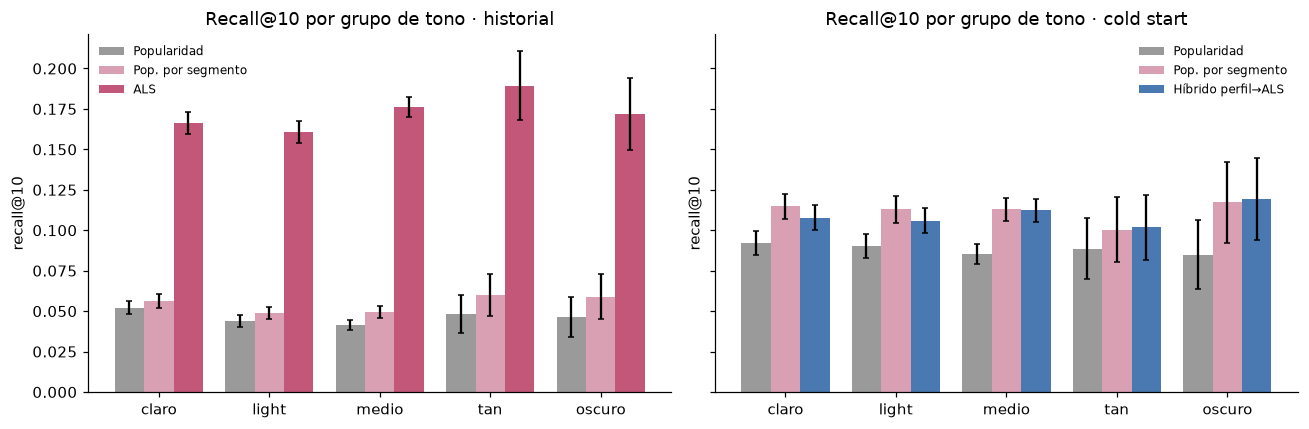

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, esc in zip(axes, ["historial", "cold start"]):
    t = tono[(tono.escenario == esc) & tono.tone_group.isin(TONE_GROUP_ORDER)]
    modelos = t.modelo.unique()
    w = 0.8 / len(modelos)
    for i, m in enumerate(modelos):
        tm = t[t.modelo == m].set_index("tone_group").reindex(TONE_GROUP_ORDER)
        ax.bar(np.arange(5) + i * w, tm["mean"], w, yerr=1.96 * tm["±"], color=COLORES[m], label=m, capsize=2)
    ax.set_xticks(np.arange(5) + w * (len(modelos) - 1) / 2, TONE_GROUP_ORDER)
    ax.set(title=f"Recall@10 por grupo de tono · {esc}", ylabel="recall@10")
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "02_recall_por_tono.png"); plt.show()

## 7 · Un hallazgo: los perfiles incompletos son "de otra época"

En la tabla anterior, las personas de tono **desconocido** tienen un recall muy superior al resto. Y el mejor segmento fue el **perfil completo** (tono, tipo, ojos y pelo). ¿Los ojos y el pelo predicen el skincare? Sospechoso. Investigamos.

In [13]:
from src.data import PROFILE_COLS
s.users["campos_faltantes"] = (s.users[PROFILE_COLS] == "desconocido").sum(axis=1)

vc = s.val_cold.join(s.users.campos_faltantes, on="author_id")
resumen_falt = pd.DataFrame({
    "personas": vc.drop_duplicates("author_id").campos_faltantes.value_counts().sort_index(),
    "año mediano de sus reseñas": vc.groupby("campos_faltantes").submission_time.median().dt.year,
    "% de positivos en el top 10 de productos": vc.groupby("campos_faltantes").product_id.apply(
        lambda p: p.value_counts(normalize=True).head(10).sum()),
})
for m in ["Popularidad", "Pop. por segmento", "Híbrido perfil→ALS"]:
    r = resultados[(m, "cold start")].join(s.users.campos_faltantes)
    resumen_falt[f"recall · {m}"] = r.groupby("campos_faltantes").recall.mean()
display(resumen_falt)

,personas,año mediano de sus reseñas,% de positivos en el top 10 de productos,recall · Popularidad,recall · Pop. por segmento,recall · Híbrido perfil→ALS
campos_faltantes,,,,,,
0,16345,2020,0.0728,0.0780,0.0920,0.0931
1,504,2022,0.1077,0.0622,0.1098,0.0293
2,1348,2011,0.2754,0.2125,0.3453,0.2958
3,1150,2015,0.2646,0.1870,0.3024,0.2910
4,2161,2016,0.2041,0.1469,0.2306,0.2193


**Qué está pasando.** Las personas con campos vacíos escribieron sus reseñas años antes (mediana 2011–2016 contra 2020). Probablemente Sephora agregó esas preguntas al formulario más tarde. En esa época había menos productos y las reseñas estaban más concentradas, así que adivinar es más fácil.

El patrón de faltantes funciona como un **reloj escondido**: "no tiene color de ojos" significa "reseñó hace mucho". El segmento "perfil completo" gana, en buena parte, porque aprende la época y no la piel.

**Qué hacemos con esto:**
1. Es una **fuga de información sutil**. No es trampa (el dato está disponible al momento de recomendar), pero infla los resultados y confunde la interpretación ("el perfil de piel predice mucho" sería una conclusión falsa).
2. Desde ahora reportamos también la métrica **solo para personas con perfil completo**. Es la población realista (una persona que hoy entra a Sephora y completa su perfil) y es la comparación justa entre modelos.

In [14]:
completo = s.users.index[s.users.campos_faltantes == 0]
filas = []
for (m, e), r in resultados.items():
    rc = r[r.index.isin(completo)]
    filas.append({"modelo": m, "escenario": e, "recall@10 (todos)": r.recall.mean(),
                  "recall@10 (perfil completo)": rc.recall.mean(), "± (perfil completo)": rc.recall.std() / np.sqrt(len(rc)),
                  "personas con perfil completo": len(rc)})
tabla_completo = pd.DataFrame(filas).set_index(["escenario", "modelo"]).sort_index()
display(tabla_completo)
tabla_completo.to_csv(ROOT / "reports" / "02_baselines_val_perfil_completo.csv")

recall@10 (todos)  recall@10 (perfil completo)  \
escenario  modelo                                                               
cold start Híbrido perfil→ALS             0.1275                       0.0931   
           Pop. por segmento              0.1334                       0.0920   
           Popularidad                    0.0988                       0.0780   
historial  ALS                            0.1693                       0.1679   
           Pop. por segmento              0.0547                       0.0482   
           Popularidad                    0.0467                       0.0434   

                               ± (perfil completo)  \
escenario  modelo                                    
cold start Híbrido perfil→ALS               0.0021   
           Pop. por segmento                0.0021   
           Popularidad                      0.0019   
historial  ALS                              0.0019   
           Pop. por segmento                0.0011   
           Popularidad                      0.0010   

                               personas con perfil completo  
escenario  modelo                                            
cold start Híbrido perfil→ALS                         16345  
           Pop. por segmento                          16345  
           Popularidad                                16345  
historial  ALS                                        38760  
           Pop. por segmento                          38760  
           Popularidad                                38760

## 8 · Sesgo de popularidad: ¿qué recomienda cada modelo?

Medimos qué proporción de las recomendaciones cae en el **top 2%** de productos más populares (los ~47 con más positivos en train).

In [15]:
top_pop = set(np.argsort(-pop.scores)[: int(0.02 * N)])
filas = []
for (m, e), r in resultados.items():
    recs = np.concatenate(r.top.to_numpy())
    filas.append({"modelo": m, "escenario": e, "% recs del top 2% popular": np.isin(recs, list(top_pop)).mean(),
                  "productos distintos recomendados": np.unique(recs).size})
display(pd.DataFrame(filas).set_index(["escenario", "modelo"]).sort_index())

% recs del top 2% popular  \
escenario  modelo                                          
cold start Híbrido perfil→ALS                     0.8061   
           Pop. por segmento                      0.8586   
           Popularidad                            1.0000   
historial  ALS                                    0.1917   
           Pop. por segmento                      0.8936   
           Popularidad                            1.0000   

                               productos distintos recomendados  
escenario  modelo                                                
cold start Híbrido perfil→ALS                               113  
           Pop. por segmento                                618  
           Popularidad                                       10  
historial  ALS                                             1153  
           Pop. por segmento                                734  
           Popularidad                                       22

## 9 · Conclusiones

### La vara que la red tiene que superar (validación)

| Escenario | Mejor baseline | Recall@10 | Recall@10 (perfil completo) | Popularidad, como referencia |
|---|---|---|---|---|
| **Con historial** | ALS (64 factores, alpha 50, reg 20) | **16,9%** | 16,8% | 4,7% |
| **Cold start** | Pop. por segmento ≈ Híbrido perfil→ALS | 13,3% / 12,8% | **9,2% / 9,3%** | 9,9% (7,8% con perfil completo) |

Al azar daría 0,4%.

### Lo que aprendimos

**1. Con historial, el historial manda.** ALS multiplica por 3,6 a la popularidad. Saber qué te gustó antes vale mucho más que saber tu tipo de piel: la popularidad por segmento apenas mejora a la popularidad global (5,5% contra 4,7%).

**2. En cold start, el perfil de piel ayuda, pero poco.** Entre personas con perfil completo, pasar de popularidad (7,8%) a usar el perfil (9,2–9,3%) suma ~1,5 puntos: **un 19% de mejora relativa**. Es real (los intervalos no se superponen), pero modesto. El híbrido lineal no le gana a contar popularidad por segmento. **Este es el desafío de la red**: ¿puede sacarle más jugo al perfil combinándolo de forma no lineal y con los ingredientes de los productos?

**3. Un hallazgo metodológico: los perfiles incompletos son un "reloj escondido".** Las personas con campos vacíos reseñaron años antes (mediana 2011–2016 contra 2020), cuando el catálogo era más chico y las reseñas estaban más concentradas. Su recall es 2–3 veces mayor, e inflaba los resultados generales (13,3% → 9,2% al sacarlas). Desde ahora, **la comparación principal en cold start es sobre personas con perfil completo.**

**4. No aparece una brecha en contra de los tonos oscuros, al menos en los baselines.** En los dos escenarios, el grupo *oscuro* tiene un recall igual o algo mayor que los tonos claros (ALS: 17,2% contra 16,1–16,6%). Con ~1.100 casos, el margen de error es de ±2,3 puntos (al 95%), así que podemos descartar brechas grandes pero no chicas. Es un resultado distinto del esperado, y por eso interesante. La pregunta para la red pasa a ser **si un modelo más complejo *introduce* una brecha** que los baselines no tienen.

**5. Sesgo de popularidad.** El híbrido recomienda solo **113 productos distintos** a 21 mil personas, y el 81% de sus recomendaciones es del top 2% de productos más populares. El ALS es mucho más diverso (1.153 productos, 19% del top 2%). Un buen modelo de cold start debería acertar más **sin** volverse un "más de lo mismo".

### Detalles de los hiperparámetros
- **ALS**: más alpha ayuda (darle más peso a los positivos observados). La regularización óptima quedó en 20; las diferencias entre 5 y 50 son de menos de 0,3 puntos.
- **Híbrido**: conviene usar **a todas** las personas para la regresión (`min_pos = 1`), aunque sus vectores sean ruidosos. Más datos le ganan a datos más limpios.
- **Segmento**: `alpha` casi no importa entre 10 y 1.000; los segmentos son lo bastante grandes.

### Para el paso 3 (la red two-tower)
- Comparar contra **ALS** con historial (16,9%) y contra **pop. por segmento / híbrido** en cold start (9,2–9,3% con perfil completo).
- Reportar siempre: recall y NDCG, por tono, sobre la población con perfil completo, y la cobertura.
- Test sigue sin tocarse.